# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 4 Classification |
| Owner (name) | Hartie Omuruon |
| Registration number | COM/0084/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |

**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [ ]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "4"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [ ]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [ ]:

# Task 4: Load the prepared Credit Risk Dataset

# Use the dataset created in Task 2.2
DATA_FILE = "data/clean_credit.csv"

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Display the number of records and columns
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

# Check the default classification target
print("\nLoan default counts:")
print(df["loan_status"].value_counts())


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



Loan default counts:
loan_status
0    25321
1     7088
Name: count, dtype: int64



## Task 4(a): Prepare the Classification Target

In this section, I prepare the loan default classification target, calculate class percentages, split the data into training and testing sets, and compare logistic regression with and without class balancing.


In [ ]:

# Task 4(a): Prepare the classification data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set our classification target
# 0 = No default, 1 = Default
y = df["loan_status"].astype(int)

# Use numeric features already prepared in Task 2.2
# Exclude the target and rate-related columns
X = df.select_dtypes(include="number").drop(
    columns=[
        "loan_status",
        "loan_int_rate",
        "rate_imputed"
    ]
)

# Display loan counts and percentages
print("LOAN DEFAULT COUNTS:")
print(y.value_counts().sort_index())

print("\nLOAN DEFAULT PERCENTAGES:")
print((y.value_counts(normalize=True)
       .sort_index() * 100).round(2))

# Split the dataset into 80% training, 20% testing
# Stratify preserves the default proportions
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Fit the scaler using training data only
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns,
    index=X_test_raw.index
)

# Display train-test results
print("\nTRAIN-TEST SPLIT")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", X_train.shape[1])

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True)
       .sort_index() * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True)
       .sort_index() * 100).round(2))

print("\nClassification data prepared successfully!")


LOAN DEFAULT COUNTS:
loan_status
0    25321
1     7088
Name: count, dtype: int64

LOAN DEFAULT PERCENTAGES:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

TRAIN-TEST SPLIT
Training rows: 25927
Testing rows: 6482
Features: 19

Training class percentages:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

Testing class percentages:
loan_status
0    78.12
1    21.88
Name: proportion, dtype: float64

Classification data prepared successfully!


In [ ]:

# Task 4(a): Compare normal and balanced Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Train the normal model
log_reg_normal = LogisticRegression(
    max_iter=2000,
    random_state=42
)
log_reg_normal.fit(X_train, y_train)

# Train the balanced model
log_reg_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)
log_reg_balanced.fit(X_train, y_train)

# Compare their test predictions
comparison_rows = []

for name, model in [
    ("Normal", log_reg_normal),
    ("Balanced", log_reg_balanced)
]:
    predictions = model.predict(X_test)

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions)
    })

# Show the results
comparison = pd.DataFrame(comparison_rows)

print("LOGISTIC REGRESSION COMPARISON")
display(comparison.round(4))


LOGISTIC REGRESSION COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,Normal,0.8517,0.7238,0.5212,0.6060
1,Balanced,0.8005,0.5292,0.7997,0.6369



## Task 4(b): Logistic Regression and Confusion Matrix

This section evaluates the balanced Logistic Regression model using a confusion matrix, classification report and predicted default probabilities.


CONFUSION MATRIX
[[4055 1009]
 [ 284 1134]]


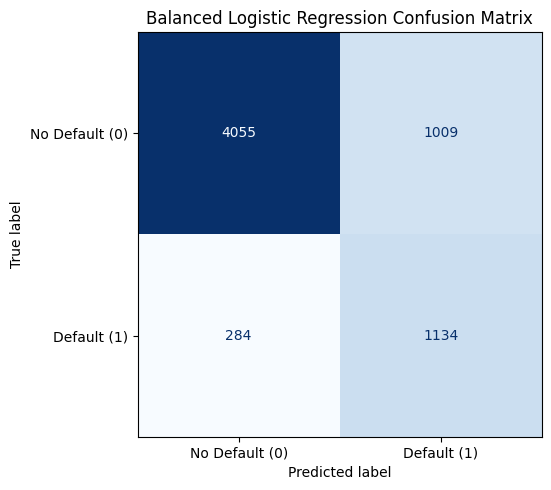


CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No Default       0.93      0.80      0.86      5064
     Default       0.53      0.80      0.64      1418

    accuracy                           0.80      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.85      0.80      0.81      6482


FIRST FIVE DEFAULT PROBABILITIES
[0.4806 0.6597 0.6587 0.4173 0.9085]

Saved: outputs/confusion_matrix.png


In [ ]:

# Task 4(b): Evaluate Logistic Regression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Select the balanced logistic regression model
log_reg = log_reg_balanced

# Predict loan default classes
y_pred = log_reg.predict(X_test)

# Predict probabilities of default
y_prob = log_reg.predict_proba(X_test)[:, 1]

# Create the required confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
print("CONFUSION MATRIX")
print(cm)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default (0)", "Default (1)"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Balanced Logistic Regression Confusion Matrix")
plt.tight_layout()

# Save the required chart
plt.savefig("outputs/confusion_matrix.png", dpi=150)

# Show the chart
plt.show()

# Display model evaluation results
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Default", "Default"]
))

# Display the first five predicted default probabilities
print("\nFIRST FIVE DEFAULT PROBABILITIES")
print(np.round(y_prob[:5], 4))

print("\nSaved: outputs/confusion_matrix.png")



## Task 4(c): Other Classification Models

In this section, I train K-Nearest Neighbours models with k values of 3, 5 and 7, and a Gaussian Naive Bayes classifier. I compare their performance using accuracy, precision, recall and F1-score.


In [ ]:

# Task 4(c): Train KNN and Gaussian Naive Bayes

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store all our additional classifiers
other_models = {}

# Train KNN using k = 3, 5 and 7
for k in [3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=k)

    # Train using the scaled training data
    model.fit(X_train, y_train)

    other_models[f"KNN k={k}"] = model

# Train Gaussian Naive Bayes
naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)

other_models["Gaussian Naive Bayes"] = naive_bayes

# Evaluate each model on the test data
other_rows = []

for name, model in other_models.items():

    predictions = model.predict(X_test)

    other_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create the comparison table
other_results = pd.DataFrame(other_rows)

print("KNN AND NAIVE BAYES RESULTS")
display(other_results.round(4))

print("\nOther classifiers completed successfully!")


KNN AND NAIVE BAYES RESULTS


,Model,Accuracy,Precision,Recall,F1
0,KNN k=3,0.8898,0.8247,0.6305,0.7146
1,KNN k=5,0.8929,0.8642,0.6058,0.7123
2,KNN k=7,0.8903,0.8765,0.5804,0.6983
3,Gaussian Naive Bayes,0.8220,0.5782,0.6883,0.6285



Other classifiers completed successfully!


In [ ]:

# Task 4(c): Train and evaluate a Support Vector Machine

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Select 5,000 training records to make SVM faster
# Stratify to maintain the default proportions
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=5000,
    stratify=y_train,
    random_state=42
)

# Create the SVM classifier
svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# Train the model
svm.fit(X_svm_train, y_svm_train)

# Predict default classes on the test set
svm_predictions = svm.predict(X_test)

# Calculate evaluation metrics
svm_results = pd.DataFrame([{
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, svm_predictions),
    "Precision": precision_score(
        y_test, svm_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, svm_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, svm_predictions, zero_division=0
    )
}])

# Store the model for the final comparison
other_models["SVM"] = svm

# Display results
print("SUPPORT VECTOR MACHINE RESULTS")
display(svm_results.round(4))

print("SVM training records:", len(X_svm_train))
print("SVM testing records:", len(X_test))

print("\nSVM training and evaluation completed!")


SUPPORT VECTOR MACHINE RESULTS


,Model,Accuracy,Precision,Recall,F1
0,SVM,0.9016,0.9004,0.6185,0.7333


SVM training records: 5000
SVM testing records: 6482

SVM training and evaluation completed!



## Task 4(d): Classification Model Comparison

This section compares Logistic Regression, K-Nearest Neighbours, Gaussian Naive Bayes and Support Vector Machine models using accuracy, precision, recall and F1-score.


In [ ]:

# Task 4(d): Compare all classification models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect all the trained classifiers
all_classifiers = {
    "Logistic Normal": log_reg_normal,
    "Logistic Balanced": log_reg_balanced,
    **other_models
}

# Create a list to store model results
comparison_rows = []

# Evaluate every model using the same test set
for name, model in all_classifiers.items():

    # Predict the loan default classes
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create the required results table
results_clf = pd.DataFrame(comparison_rows)

# Sort models by F1-score, highest first
results_clf = results_clf.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

# Display the comparison
print("FINAL CLASSIFICATION MODEL COMPARISON")
display(results_clf.round(4))

# Identify models with the highest F1 and recall
best_f1 = results_clf.loc[
    results_clf["F1"].idxmax(), "Model"
]

best_recall = results_clf.loc[
    results_clf["Recall"].idxmax(), "Model"
]

print("\nHighest F1-score:", best_f1)
print("Highest default recall:", best_recall)

print("\nClassification comparison completed!")


FINAL CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,SVM,0.9016,0.9004,0.6185,0.7333
1,KNN k=3,0.8898,0.8247,0.6305,0.7146
2,KNN k=5,0.8929,0.8642,0.6058,0.7123
3,KNN k=7,0.8903,0.8765,0.5804,0.6983
4,Logistic Balanced,0.8005,0.5292,0.7997,0.6369
5,Gaussian Naive Bayes,0.8220,0.5782,0.6883,0.6285
6,Logistic Normal,0.8517,0.7238,0.5212,0.6060



Highest F1-score: SVM
Highest default recall: Logistic Balanced

Classification comparison completed!


ROC AUC: 0.8727


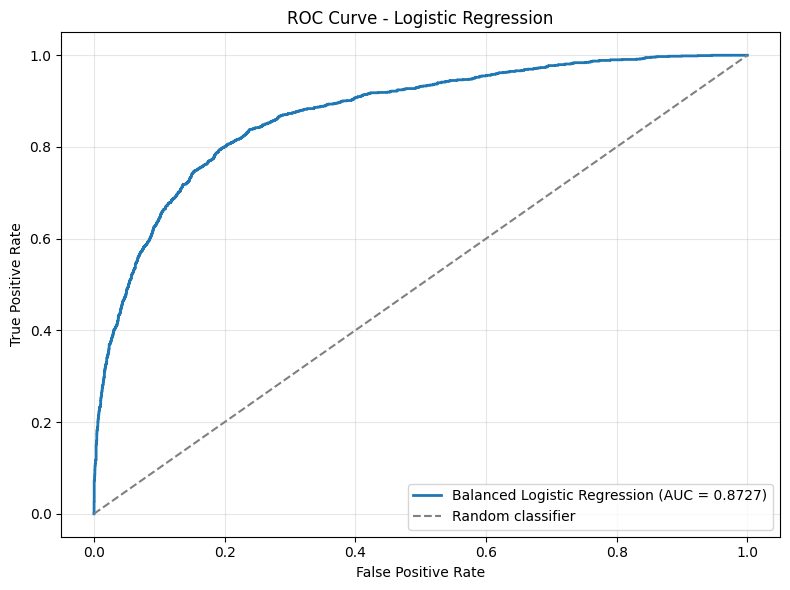

Saved: outputs/roc_curve.png
AUC variable created successfully!


In [ ]:

# Task 4(d): Plot ROC curve and calculate AUC

# Import ROC evaluation tools
from sklearn.metrics import roc_curve, roc_auc_score

# Use the balanced Logistic Regression model
log_reg = log_reg_balanced

# Predict the probability of default (class 1)
y_prob = log_reg.predict_proba(X_test)[:, 1]

# Calculate false positive and true positive rates
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC and store it in the required variable
auc = roc_auc_score(y_test, y_prob)

# Display AUC
print("ROC AUC:", round(auc, 4))

# Create the ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Balanced Logistic Regression (AUC = {auc:.4f})"
)

# Draw a diagonal line representing random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

# Add title and axis labels
plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

# Add legend and grid
plt.legend()
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/roc_curve.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/roc_curve.png")
print("AUC variable created successfully!")



### Task 4(c): Exam Skill — Comparing Classifiers

**Logistic Regression vs K-Nearest Neighbours (KNN)**

Logistic Regression estimates the probability that a loan will default using a mathematical function based on borrower characteristics.

KNN predicts whether a loan will default by examining the classes of the most similar historical loans.

In my experiment, KNN with k=3 achieved an F1-score of 0.7146, while Balanced Logistic Regression achieved 0.6369. However, Balanced Logistic Regression had higher default recall (0.7997), making it better at detecting actual defaulters.

**Naive Bayes vs Support Vector Machine (SVM)**

Gaussian Naive Bayes uses probability calculations and assumes that features are conditionally independent given the loan class.

SVM uses a decision boundary to separate borrowers predicted to default from those predicted not to default.

My SVM achieved 90.16% accuracy and an F1-score of 0.7333, while Naive Bayes achieved 82.20% accuracy and an F1-score of 0.6285.

SVM performed better overall in these measures, but Naive Bayes achieved higher default recall (0.6883 compared with 0.6185).


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# c1. <what this cell does>


## Written answer

### Task 4: Written Answer — Classification Model Recommendation

I compared seven classification models to predict loan defaults in the Credit Risk Dataset.

SVM achieved the highest accuracy of **90.16%** and F1-score of **0.7333**, making it the strongest model by these overall measures.

However, I would recommend **Balanced Logistic Regression for further evaluation as a loan-risk screening model** because it achieved the highest default recall of **79.97%**, compared with SVM's 61.85%.

Accuracy alone is misleading because only 21.87% of loans defaulted, so a model could achieve high accuracy by predicting most loans would not default while missing many actual defaulters.

Balanced Logistic Regression achieved an ROC-AUC of **0.8727**, indicating good discrimination, although it also incorrectly flagged 1,009 non-defaulting loans for review; therefore, the SACCO should assess the costs of missed defaults and false alarms before deployment.

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [ ]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 4
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
